# Ⅰ第6回 演習2 相関トークンを入れて学習する

**問い**：訓練画像のクラス A にだけ赤い四角を入れると，CNN は写真の中身と赤い四角のどちらで当てるようになるか．

| 用語 | 意味 |
|---|---|
| 相関トークン | 本来の答えとは関係ないのに，訓練データでは正解ラベルとほぼ必ず一緒に出てくる目印（ここでは右下の赤い四角） |
| ショートカット学習 | モデルが見てほしい特徴ではなく，相関トークンのような楽な手がかりで当てるようになること |
| 反転テスト | 訓練で A に入れた目印を，テストでは B に入れる（目印を付けるクラスを入れ替える）．「B に赤い四角を入れる」の正解率が大きく落ちれば，目印で当てていた |

- 写真は第4回の `assets/mydata/` を使う（無ければケーブル画像で進む）．元の写真は書き換えない
- シード 0 で 1 回ずつ．5 回で判定するのは演習3

## (0) 準備

In [1]:
# 授業用フォルダ（AI_TD）のルートを import パスに追加する（ノートブックをどこから開いても動く）
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".dlcourse_root").exists())
sys.path.insert(0, str(ROOT))
print("作業フォルダ:", ROOT)

作業フォルダ: /Users/itagakisogo/AI_TD


## (1) 赤い四角を入れる関数を書く

画像は `x`（3×64×64，値は 0〜1．0 番目が R・1 番目が G・2 番目が B）．右下の 8×8 画素を赤にした **新しい画像** を返す．

- 右下の 8×8 画素は `y[:, -8:, -8:]`（`-8:` は「後ろから 8 個」）
- `x` をそのまま書き換えると元の写真まで変わるので，`y = x.clone()` でコピーしてから書く

<details><summary>ヒント（分からないときに開く・ほぼ答え）</summary>

```python
def add_token(x):
    y = x.clone()             # x を書き換えないようコピーする
    y[0, -8:, -8:] = 1.0      # R
    y[1, -8:, -8:] = 0.0      # G
    y[2, -8:, -8:] = 0.0      # B
    return y
```

</details>

In [4]:
def add_token(x):
    y = x.clone()                   # x を書き換えないようコピーする
    y[0, -8:, -8:] = 1             # 右下の 8×8 画素を赤（R=1, G=0, B=0）にする（3 行）
    y[1, -8:, -8:] = 0
    y[2, -8:, -8:] = 0
    return y

from common.shortcut import check_token
check_token(add_token)

OK｜右下の 8×8 画素が赤になった


## (2) 訓練画像を見る（クラス A にだけ四角）

クラス A（四角を入れる）＝ deffense｜それ以外 ＝ ['offense']


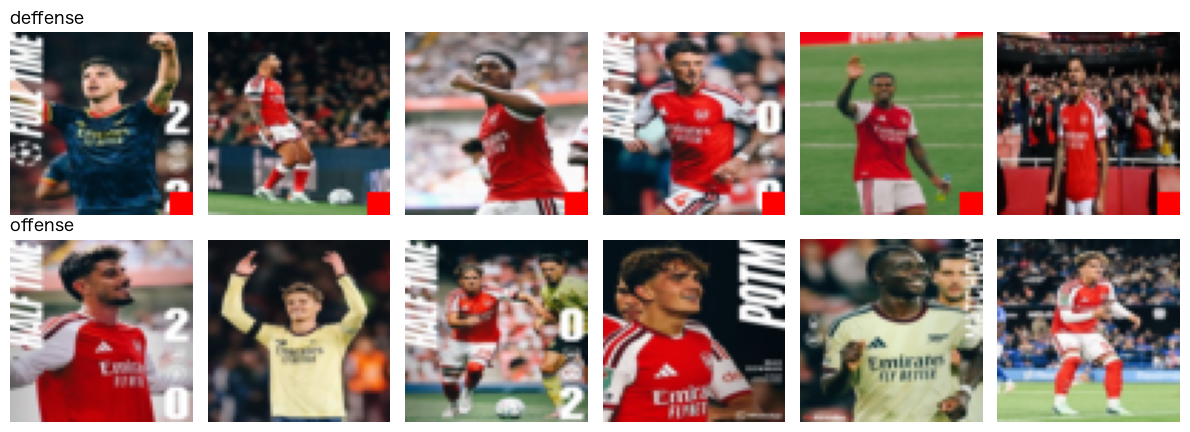

In [5]:
import matplotlib.pyplot as plt
from common.mydata import image_dir, loaders
from common.shortcut import TOKEN_CLASS
plt.rcParams["font.family"] = ["Hiragino Sans", "sans-serif"]   # Mac の日本語フォント（文字化け防止）

IMAGE_DIR = image_dir()
train_loader, _, _, classes = loaders(seed=0, size=64, root=IMAGE_DIR)
print(f"クラス A（四角を入れる）＝ {classes[TOKEN_CLASS]}｜それ以外 ＝ {classes[1:]}")
fig, axes = plt.subplots(2, 6, figsize=(12, 4.4))
for row, label in enumerate([TOKEN_CLASS, 1]):
    xs = [x for x, y in train_loader.dataset if y == label][:6]
    for ax, x in zip(axes[row], xs):
        ax.imshow((add_token(x) if label == TOKEN_CLASS else x).permute(1, 2, 0))
        ax.axis("off")
    axes[row][0].set_title(classes[label], loc="left")
plt.tight_layout()
plt.show()

## 予測（実行する前に書く）

このセルをダブルクリックして書き込む．CNN をクラス A に四角を入れた訓練画像で学習したとき，3 つのテストの正解率は：

| テスト | 付け方 | 予測（%） |
|---|---|---|
| 四角なし | どの写真にも付けない | 30% |
| A に赤い四角を入れる | クラス A にだけ付ける（訓練と同じ付け方） | 50% |
| B に赤い四角を入れる | クラス B（A 以外）にだけ付ける（訓練と逆） | 40% |

## (3) 四角なし・四角ありで学習して，3 つのテストで測る

学習は第4回の CNN と同じ（64×64・20 エポック・Adam・lr=0.001）．テストの写真は 3 つとも同じで，四角の付け方だけが違う（四角なし・A に赤い四角を入れる・B に赤い四角を入れる）．

In [6]:
import pandas as pd
from common.device import get_device
from common.logger import ResultLogger
from common.shortcut import TESTS, run

device = get_device()
logger = ResultLogger(None, "member1", course="c1", day="d6", exercise="ex2", device=device)
rows = []
for token_train in [False, True]:
    r = run("CNN", token_train, seed=0, root=IMAGE_DIR, device=device)
    train = "クラス A に四角" if token_train else "四角なし"
    logger.log_many({f"acc_{t}": a for t, a in r["acc"].items()}, condition=f"{IMAGE_DIR.name}_CNN_token{int(token_train)}", seed=0)
    rows.append({"訓練": train, **{TESTS[t]: a * 100 for t, a in r["acc"].items()}})
df = pd.DataFrame(rows).set_index("訓練")
print(df.round(1).to_string())
print(f"テストは {r['n_test']} 枚．1 枚で {100 / r['n_test']:.1f} ポイント動く")

           四角なし  A に赤い四角を入れる  B に赤い四角を入れる
訓練                                       
四角なし       41.7         41.7         66.7
クラス A に四角  58.3         75.0         16.7
テストは 12 枚．1 枚で 8.3 ポイント動く


## 振り返り（提出）

下のセルの `""" """` の中に書いて実行する（それぞれ 1〜2 文）．**2 と 3 は，(3) の表の自分の数値（例 100.0）を 1 つ以上入れて根拠にする**．入っていないと止まる．

In [ ]:
from common.shortcut import evidence_check
A1 = """予測と比べて，当たったこと・外れたこと：Aに赤い四角を入れた時に一番正解率が高くなること。四角無しよりもBに四角を入れた時の方が正解率が低くなること。"""
A2 = """クラス A に四角を入れて学習したCNN は，写真の何を見て当てていたと言えるか（根拠：「A に赤い四角を入れる」と「B に赤い四角を入れる」の差，「四角なしで学習」の行との違い）：「四角なしで学習」したモデルと異なり、「Aに四角」で学習したモデルはBに四角を付けると正解率が75.0%から16.7%へ急落しているから、赤い四角のついた画像を無条件でクラスAと誤判定していた。CNNは画像本来の特徴ではなく、「赤い四角の有無」を主な判断材料として学習してしまったことがわかる。"""
A3 = """「A に赤い四角を入れる」のテストだけを見ていたら，このモデルをどう評価していたか：最も高い正解率（75.0%）が出ているため、モデルが画像本来の特徴を捉えて正しく分類できていると評価してしまう可能性があった。"""
A4 = """「B に赤い四角を入れる」の正解率が 50%（2 クラスで当てずっぽう）より低くなるのはなぜか：モデルが「赤い四角＝クラスA」という関係を強力に学習しているため、赤い四角を付けたクラスBの画像の大半を「クラスA」と誤判定してしまうから"""
evidence_check({"振り返り2": A2, "振り返り3": A3}, df)

振り返り2 OK：引用した数値 16.7, 75.0
振り返り3 OK：引用した数値 75.0
